# One-quarter-ahead US unemployment

A forecast desk has to publish next quarter's unemployment rate before that quarter's national accounts exist. The question is which working distribution to attach to a short list of lagged macro variables, judged on quarters that had not happened yet.

The series is the frozen extract shipped with statsmodels as `macrodata` and packaged here as `mb.datasets.usmacro`: US quarterly aggregates from 1959Q1 through 2009Q3, assembled from FRED (Federal Reserve Economic Data) in 2009. Pulling the same FRED codes today would pick up later benchmark revisions, so this page does not refresh the file. M1 is not used. Retail sweeps after 1994 changed what that series measures, and this regression does not need it.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | the unemployment rate in the next quarter |
| **Observed response** | BLS (Bureau of Labor Statistics) unemployment rate, percent, on the 2009 FRED vintage |
| **Estimand** | held-out mean absolute error, and the mean negative log density where the model has one |
| **Units** | percentage points; nats per quarter |
| **Sampling unit** | one row is one US quarter on the frozen 2009 data vintage |
| **Dependence** | Quarters are serially related; the training, tuning and test periods preserve time order. |
| **Split and tuning** | fit through 1989Q4; choose boosting steps on 1980–89 only; score 1990Q1–2009Q3 |
| **Information** | lagged unemployment, lagged CPI (consumer price index) inflation, lagged 3-month bill rate, lagged real GDP growth |
| **Uncertainty** | fitted predictive distributions are scored; no resampling confidence intervals for score differences are reported |
| **Claim type** | predictive comparisons conditional on the recorded covariates; no causal effects are estimated |
| **What this does not estimate** | a causal effect of policy, a density for M1, or a fit on later-revised data |

:::


In [1]:
import io
import warnings
from contextlib import redirect_stdout

import altair as alt
import numpy as np
import polars as pl
import statsmodels.api as sm
from IPython.display import display
from scipy import stats
from statsmodels.miscmodels.tmodel import TLinearModel
from statsmodels.robust.norms import HuberT
from statsmodels.robust.robust_linear_model import RLM

import mboostrs as mb

raw = mb.datasets.usmacro(output="polars").sort(["year", "quarter"])
frame = raw.with_columns(
    (pl.col("realgdp") / pl.col("realgdp").shift(1) - 1).alias("gdp_growth")
).with_columns(
    pl.col("unemp").shift(1).alias("unemp_l1"),
    pl.col("infl").shift(1).alias("infl_l1"),
    pl.col("tbilrate").shift(1).alias("tbill_l1"),
    pl.col("gdp_growth").shift(1).alias("gdp_growth_l1"),
).drop_nulls()

early = frame.filter(pl.col("year") < 1980)
valid = frame.filter((pl.col("year") >= 1980) & (pl.col("year") < 1990))
train = frame.filter(pl.col("year") < 1990)
test = frame.filter(pl.col("year") >= 1990)
crisis = (test["year"] >= 2008).to_numpy()
formula = "unemp ~ unemp_l1 + infl_l1 + tbill_l1 + gdp_growth_l1"
columns = ["unemp_l1", "infl_l1", "tbill_l1", "gdp_growth_l1"]
print(
    f"{frame.height} quarters after lags, {early.height} before 1980, "
    f"{valid.height} in 1980-89, {train.height} through 1989, {test.height} from 1990, "
    f"{int(crisis.sum())} from 2008Q1"
)


201 quarters after lags, 82 before 1980, 40 in 1980-89, 122 through 1989, 79 from 1990, 7 from 2008Q1


In [2]:
def design(data):
    return sm.add_constant(data.select(columns).to_numpy())


y_train = train["unemp"].to_numpy()
y_test = test["unemp"].to_numpy()
x_train, x_test = design(train), design(test)

ols = sm.OLS(y_train, x_train).fit()
ols_mu = np.asarray(ols.predict(x_test), dtype=float)
ols_sd = float(np.sqrt(np.mean((y_train - ols.fittedvalues) ** 2)))
ols_nll = float(-stats.norm.logpdf(y_test, ols_mu, ols_sd).mean())
ols_crisis = float(-stats.norm.logpdf(y_test[crisis], ols_mu[crisis], ols_sd).mean())

rlm = RLM(y_train, x_train, M=HuberT()).fit()
rlm_mu = np.asarray(rlm.predict(x_test), dtype=float)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    with redirect_stdout(io.StringIO()):
        t_model = TLinearModel(y_train, x_train).fit(method="bfgs", disp=False, maxiter=400)
t_mu = np.asarray(t_model.predict(x_test), dtype=float)
t_df = float(t_model.params[-2])
t_scale = abs(float(t_model.params[-1]))
t_nll = float(-stats.t.logpdf(y_test, t_df, loc=t_mu, scale=t_scale).mean())
t_crisis = float(-stats.t.logpdf(y_test[crisis], t_df, loc=t_mu[crisis], scale=t_scale).mean())
t_converged = bool(t_model.mle_retvals.get("converged"))


def point_errors(mu):
    mu = np.asarray(mu, dtype=float)
    return (
        float(np.mean(np.abs(mu - y_test))),
        float(np.mean(np.abs(mu[crisis] - y_test[crisis]))),
    )


In [3]:
def validation_objective(kind, pred, y_valid, train_sd=None):
    y_valid = np.asarray(y_valid, dtype=float)
    if kind == "mae":
        return float(np.mean(np.abs(np.asarray(pred) - y_valid)))
    if kind == "gaussian-fixed":
        mu = np.asarray(pred, dtype=float).ravel()
        return float(-stats.norm.logpdf(y_valid, mu, train_sd).mean())
    if kind == "gausslss":
        return float(
            -stats.norm.logpdf(y_valid, np.asarray(pred["mu"]), np.asarray(pred["sigma"])).mean()
        )
    return float(
        -stats.t.logpdf(
            y_valid,
            np.asarray(pred["df"]),
            loc=np.asarray(pred["mu"]),
            scale=np.asarray(pred["sigma"]),
        ).mean()
    )


def choose_mstop(ctor, family, kind, cap, location_scale):
    kwargs = {"family": family, "control": mb.boost_control(cap, 0.1)}
    if location_scale:
        kwargs["method"] = "noncyclic"
    path = ctor(formula, early, **kwargs)
    y_valid = valid["unemp"].to_numpy()
    best_step, best_score = None, np.inf
    for step in range(20, cap + 1, 10):
        tuned = path.with_mstop([step] if location_scale else step)
        pred = tuned.predict(valid, type="response")
        if kind == "gaussian-fixed":
            train_mu = np.asarray(tuned.predict(early, type="response"), dtype=float).ravel()
            train_sd = float(np.sqrt(np.mean((early["unemp"].to_numpy() - train_mu) ** 2)))
            score = validation_objective(kind, pred, y_valid, train_sd)
        else:
            score = validation_objective(kind, pred, y_valid)
        if score < best_score:
            best_step, best_score = step, score
    return best_step, best_score, best_step == cap


jobs = [
    ("mboostrs glmboost Gaussian", mb.glmboost, mb.Gaussian(), "gaussian-fixed", 400, False),
    ("mboostrs glmboost Huber", mb.glmboost, mb.Huber(), "mae", 800, False),
    ("mboostrs glmboostLSS GaussianLSS", mb.glmboostLSS, mb.GaussianLSS(), "gausslss", 800, True),
    ("mboostrs glmboostLSS StudentTLSS", mb.glmboostLSS, mb.StudentTLSS(), "t", 800, True),
]
boosted = {}
for label, ctor, family, kind, cap, location_scale in jobs:
    step, score, at_cap = choose_mstop(ctor, family, kind, cap, location_scale)
    kwargs = {"family": family, "control": mb.boost_control(step, 0.1)}
    if location_scale:
        kwargs["method"] = "noncyclic"
    fit = ctor(formula, train, **kwargs)
    boosted[label] = {
        "mstop": step,
        "validation": score,
        "at_cap": at_cap,
        "fit": fit,
        "pred": fit.predict(test, type="response"),
        "kind": kind,
    }


In [4]:
rows = []


def add_row(method, mu, nll, crisis_nll, mstop=None, at_cap=None, note=""):
    point, crisis_point = point_errors(mu)
    rows.append({
        "method": method,
        "mae": point,
        "crisis_mae": crisis_point,
        "nll": nll,
        "crisis_nll": crisis_nll,
        "mstop": mstop,
        "at_cap": at_cap,
        "note": note,
    })


add_row("statsmodels OLS", ols_mu, ols_nll, ols_crisis, note=f"residual sd {ols_sd:.3f}")
add_row(
    "statsmodels RLM Huber",
    rlm_mu,
    None,
    None,
    note=f"scale {float(rlm.scale):.3f}",
)
add_row(
    "statsmodels TLinearModel",
    t_mu,
    t_nll,
    t_crisis,
    note=f"df {t_df:.2f}, scale {t_scale:.3f}, converged {t_converged}",
)

for label, item in boosted.items():
    kind, pred = item["kind"], item["pred"]
    if kind == "gaussian-fixed":
        mu = np.asarray(pred, dtype=float).ravel()
        train_mu = np.asarray(item["fit"].predict(train, type="response"), dtype=float).ravel()
        sd = float(np.sqrt(np.mean((y_train - train_mu) ** 2)))
        nll = float(-stats.norm.logpdf(y_test, mu, sd).mean())
        crisis_nll = float(-stats.norm.logpdf(y_test[crisis], mu[crisis], sd).mean())
        note = f"residual sd {sd:.3f}"
    elif kind == "gausslss":
        mu = np.asarray(pred["mu"], dtype=float).ravel()
        sigma = np.asarray(pred["sigma"], dtype=float).ravel()
        nll = float(-stats.norm.logpdf(y_test, mu, sigma).mean())
        crisis_nll = float(-stats.norm.logpdf(y_test[crisis], mu[crisis], sigma[crisis]).mean())
        note = (
            f"sigma {sigma.mean():.3f} ({sigma.min():.3f} to {sigma.max():.3f}), "
            f"corr with lagged unemployment {np.corrcoef(test['unemp_l1'].to_numpy(), sigma)[0, 1]:.2f}"
        )
        gausslss_sigma = sigma
    elif kind == "t":
        mu = np.asarray(pred["mu"], dtype=float).ravel()
        sigma = np.asarray(pred["sigma"], dtype=float).ravel()
        df_hat = np.asarray(pred["df"], dtype=float).ravel()
        nll = float(-stats.t.logpdf(y_test, df_hat, loc=mu, scale=sigma).mean())
        crisis_nll = float(
            -stats.t.logpdf(
                y_test[crisis], df_hat[crisis], loc=mu[crisis], scale=sigma[crisis]
            ).mean()
        )
        note = f"sigma {float(sigma.mean()):.3f}, df {float(df_hat.mean()):.2f}"
    else:
        mu = np.asarray(pred, dtype=float).ravel()
        nll, crisis_nll = None, None
        note = "no density; adaptive delta"
    add_row(label, mu, nll, crisis_nll, item["mstop"], item["at_cap"], note)

summary = pl.DataFrame(rows).sort("nll", nulls_last=True)
huber_row = summary.filter(pl.col("method") == "mboostrs glmboost Huber")
huber_cap_note = (
    "the last grid point, so that choice is not interior"
    if bool(huber_row["at_cap"][0])
    else "an interior step of the 800-step grid"
)
display(summary)


method,mae,crisis_mae,nll,crisis_nll,mstop,at_cap,note
str,f64,f64,f64,f64,i64,bool,str
"""mboostrs glmboostLSS StudentTL…",0.18877,0.682013,-0.033452,2.082841,200,false,"""sigma 0.216, df 6.37"""
"""statsmodels TLinearModel""",0.189914,0.669973,0.062032,2.443039,null,null,"""df 4.18, scale 0.219, converge…"
"""mboostrs glmboostLSS GaussianL…",0.187996,0.641636,0.080684,3.039749,130,false,"""sigma 0.248 (0.165 to 0.514), …"
"""statsmodels OLS""",0.182241,0.606918,0.115311,2.41431,null,null,"""residual sd 0.296"""
"""mboostrs glmboost Gaussian""",0.183234,0.609451,0.118077,2.431116,110,false,"""residual sd 0.296"""
"""statsmodels RLM Huber""",0.187526,0.647468,null,null,null,null,"""scale 0.279"""
"""mboostrs glmboost Huber""",0.190514,0.685428,null,null,800,true,"""no density; adaptive delta"""


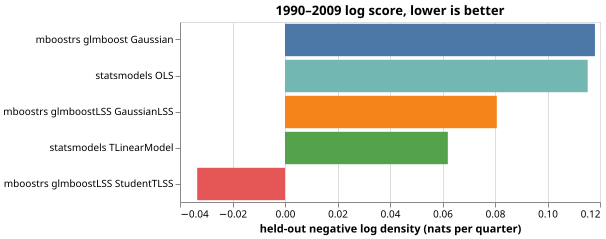

In [5]:
scored = summary.filter(pl.col("nll").is_not_null())
alt.Chart(scored).mark_bar().encode(
    x=alt.X(
        "nll:Q",
        title="held-out negative log density (nats per quarter)",
        scale=alt.Scale(zero=False),
    ),
    y=alt.Y("method:N", sort="-x", title=None),
    color=alt.Color("method:N", legend=None),
).properties(
    width=420,
    height=180,
    title="1990–2009 log score, lower is better",
)


## Results and interpretation

Lagged unemployment contributes most of the fitted point forecast. OLS puts a coefficient of {eval}`f"{float(ols.params[1]):.2f}"` on last quarter's unemployment rate. Every method's mean absolute error on 1990Q1–2009Q3 sits between {eval}`f"{float(summary['mae'].min()):.3f}"` and {eval}`f"{float(summary['mae'].max()):.3f}"` percentage points. Huber, whether statsmodels `RLM` or `glmboost` with the adaptive Huber loss, does not improve that error. The adaptive Huber search stopped at step {eval}`str(int(huber_row['mstop'][0]))`, {eval}`huber_cap_note`.

Predictive log scores distinguish the fitted distributions despite similar
point errors. On the 79 held-out quarters, boosted `StudentTLSS` (a location, scale and shape model with a Student-t distribution) scores {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboostLSS StudentTLSS')['nll'][0]):.3f}"` nats per quarter. The t maximum-likelihood fit scores {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels TLinearModel')['nll'][0]):.3f}"` (df {eval}`f"{t_df:.2f}"`, scale {eval}`f"{t_scale:.3f}"`). OLS, with one residual standard deviation of {eval}`f"{ols_sd:.3f}"`, scores {eval}`f"{ols_nll:.3f}"`. A Gaussian whose scale may depend on the same lags scores {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboostLSS GaussianLSS')['nll'][0]):.3f}"`. Lower is better.

The seven quarters from 2008Q1 through 2009Q3 assess prediction during the
financial crisis. Crisis log scores are {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboostLSS StudentTLSS')['crisis_nll'][0]):.2f}"` for the boosted t, {eval}`f"{ols_crisis:.2f}"` for OLS, {eval}`f"{t_crisis:.2f}"` for the constant-scale t, and {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboostLSS GaussianLSS')['crisis_nll'][0]):.2f}"` for the varying-scale Gaussian. That Gaussian scale moves with lagged unemployment (correlation {eval}`f"{float(np.corrcoef(test['unemp_l1'].to_numpy(), gausslss_sigma)[0, 1]):.2f}"`), but the large unemployment jumps arrive in the quarter before the lag has widened the scale, so the crisis density is worse than OLS.

Publish the OLS point forecast. The boosted Gaussian point forecast is the same number for practical purposes. Publish a Student-t distribution around it rather than one residual standard deviation. Do not switch the point forecast to Huber. Do not drive a Gaussian variance off lagged unemployment for those crisis quarters.


In [6]:
probe_fit = mb.glmboostLSS(
    formula,
    train,
    family=mb.StudentTLSS(),
    control=mb.boost_control(40, 0.1),
    method="noncyclic",
)
link = probe_fit.predict(type="link")
response = probe_fit.predict(type="response")
link_gap = {
    name: float(np.max(np.abs(
        (np.asarray(link[name]) if name == "mu" else np.exp(np.asarray(link[name])))
        - np.asarray(response[name])
    )))
    for name in ("mu", "sigma", "df")
}
scipy_ll = float(stats.t.logpdf(
    y_train,
    np.asarray(response["df"]),
    loc=np.asarray(response["mu"]),
    scale=np.asarray(response["sigma"]),
).sum())
loglik_gap = abs(float(probe_fit.logLik()) - scipy_ll)
try:
    mb.glmboost(formula, train, family=mb.StudentTLSS(), control=mb.boost_control(5, 0.1))
    glmboost_student = "accepted"
except Exception as exc:
    glmboost_student = str(exc).split("\n")[0]
implied_sd = float(
    np.mean(response["sigma"]) * np.sqrt(np.mean(response["df"]) / (np.mean(response["df"]) - 2))
)
print("link matches response", link_gap)
print("offset", probe_fit.offset)
print("logLik", float(probe_fit.logLik()), "gap", loglik_gap)
print("glmboost StudentTLSS:", glmboost_student)
print(
    "Student-t sigma",
    float(np.mean(response["sigma"])),
    "implied sd",
    implied_sd,
    "GaussianLSS sigma is already an sd",
)


link matches response {'mu': 0.0, 'sigma': 0.0, 'df': 0.0}
offset {'mu': 5.937046580701751, 'sigma': 0.25840259286008277, 'df': 1.8515302848138533}
logLik -72.81809032982149 gap 1.4210854715202004e-14
glmboost StudentTLSS: StudentTLSS is a distributional family (parameters: mu, sigma, df). glmboost() fits one predictor. Use glmboostLSS() or gamboostLSS(), for example mb.gamboostLSS(formula, data, family=mb.StudentTLSS()).
Student-t sigma 0.5204446850843248 implied sd 0.628362778560763 GaussianLSS sigma is already an sd


## API behavior and limitations

`predict` with no `type` returns the link. For `StudentTLSS` that is the mean, the log scale and the log degrees of freedom. Exponentiating the last two recovers `type="response"`. The forecast in "Results and interpretation" uses `type="response"`. The gaps reported by the probe are numerical zeros on this fit.

`offset` is the link-scale starting value (the constant the model starts from before the first step), not the fitted parameter and not a degrees of freedom. On this probe, `offset["df"]` is {eval}`f"{float(probe_fit.offset['df']):.2f}"` while the response-scale df averages {eval}`f"{float(np.mean(probe_fit.predict(type='response')['df'])):.2f}"`.

For `GaussianLSS`, `sigma` is the standard deviation. For `StudentTLSS` it is the scale of a standard t, and the standard deviation is `sigma * sqrt(df / (df - 2))` when df exceeds 2. The probe cell prints both. Treating the t scale as a standard deviation makes the interval too narrow.

`logLik()` on the probe matches the t density at the fitted parameters (gap {eval}`f"{loglik_gap:.1e}"`). `glmboost(family=StudentTLSS())` still reports an unknown family. `glmboost` does not recognise this family, a limitation of that call; the location-scale fit is `glmboostLSS`.

`TLinearModel` writes `running Tmodel initialize` to standard output during `fit`. The fitting cell redirects that line. Its scale is the same standard-t scale, not a standardized residual.
